# Adversarial Search and Games

The theory is in [README.md](./README.md) — minimax, alpha-beta pruning, move ordering and
evaluation functions. This notebook is only the code.

Three parts, each one further from the tidy diagram and closer to a real game:

1. **An abstract game tree.** Nine leaves on paper. Small enough to check by hand, which is the
   point: you can see exactly which nodes alpha-beta skips and why.
2. **Nim.** A real game, small enough to solve *exactly* — and with a known mathematical answer,
   so we can prove our search is right rather than hope it is.
3. **Connect Four.** Far too big to solve. This is where the cutoff, the evaluation function and
   move ordering stop being theory.

## Setup

In [1]:
import math
import random
import time
from dataclasses import dataclass
from typing import Any, Callable, Optional

import matplotlib.pyplot as plt

MAX, MIN = "MAX", "MIN"
INF = math.inf


def other(player: str) -> str:
    return MIN if player == MAX else MAX


@dataclass
class Stats:
    """How much work a search did. Both algorithms return the same answer;
    this is the only thing that tells them apart."""
    nodes: int = 0

    def __repr__(self) -> str:
        return f"{self.nodes} nodes"

## What a game looks like

Six functions, and the algorithms below know nothing else. Exactly as in week 3, stating the
problem in a fixed vocabulary is what lets one solver run every game.

`State` is whatever you like — a string, a tuple of pile sizes, a board. The search never looks
inside it, it only hands it back to your six methods.

`utility` is always **from MAX's point of view**. The game is zero-sum, so one number says
everything: MIN simply wants it small.

In [2]:
State = Any
Action = Any


class Game:
    def initial(self) -> State:
        """The starting position."""
        raise NotImplementedError

    def to_move(self, state: State) -> str:
        """Whose turn it is: MAX or MIN."""
        raise NotImplementedError

    def actions(self, state: State) -> list[Action]:
        """The legal moves in this position."""
        raise NotImplementedError

    def result(self, state: State, action: Action) -> State:
        """The position after playing action. Must not modify state."""
        raise NotImplementedError

    def is_terminal(self, state: State) -> bool:
        """Is the game over."""
        raise NotImplementedError

    def utility(self, state: State) -> float:
        """The payoff to MAX in a terminal state. Only called when is_terminal."""
        raise NotImplementedError

## Part 1 — a game tree on paper

Three moves for MAX at the root, three replies for MIN, then the game ends with the numbers below.
Nothing is a real game here; it is a tree with values written under it, so that every claim about
minimax and pruning can be checked by eye.

The `visited` list is instrumentation: the game records each leaf whose value was actually read.
That is what makes pruning visible.

In [3]:
TREE_CHILDREN = {
    "A": ["B", "C", "D"],
    "B": ["b1", "b2", "b3"],
    "C": ["c1", "c2", "c3"],
    "D": ["d1", "d2", "d3"],
}
TREE_LEAVES = {"b1": 3, "b2": 12, "b3": 8, "c1": 2, "c2": 4, "c3": 6, "d1": 14, "d2": 5, "d3": 2}


class TreeGame(Game):
    """A game tree given explicitly. Depth 0 is MAX, depth 1 is MIN, depth 2 are the leaves."""

    def __init__(self, children=TREE_CHILDREN, leaves=TREE_LEAVES, root="A"):
        self.children, self.leaves, self.root = children, leaves, root
        self.depth: dict[str, int] = {}
        self.visited: list[str] = []
        stack = [(root, 0)]
        while stack:
            node, d = stack.pop()
            self.depth[node] = d
            stack += [(c, d + 1) for c in self.children.get(node, [])]

    def initial(self): return self.root
    def to_move(self, s): return MAX if self.depth[s] % 2 == 0 else MIN
    def actions(self, s): return list(range(len(self.children.get(s, []))))
    def result(self, s, a): return self.children[s][a]
    def is_terminal(self, s): return s in self.leaves

    def utility(self, s):
        self.visited.append(s)      # instrumentation, not part of the game
        return self.leaves[s]

And a picture of it. Upward triangles are MAX nodes, downward triangles are MIN nodes, squares are
leaves. Later we pass `seen=` to grey out the leaves a search never looked at.

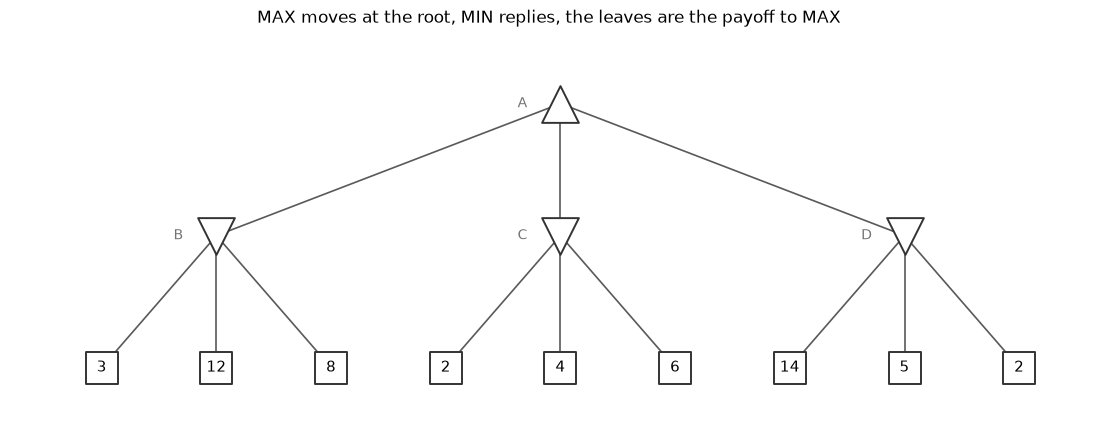

In [4]:
def tree_positions(children, root):
    pos, nxt = {}, [0.0]

    def place(n, d):
        kids = children.get(n, [])
        if not kids:
            pos[n] = (nxt[0], -d)
            nxt[0] += 1.0
        else:
            for k in kids:
                place(k, d + 1)
            pos[n] = (sum(pos[k][0] for k in kids) / len(kids), -d)

    place(root, 0)
    return pos


def draw_tree(game, values=None, seen=None, title=""):
    pos = tree_positions(game.children, game.root)
    values = values or {}
    fig, ax = plt.subplots(figsize=(11, 4.5))

    for n, kids in game.children.items():
        for k in kids:
            faded = seen is not None and k in game.leaves and k not in seen
            ax.plot([pos[n][0], pos[k][0]], [pos[n][1], pos[k][1]],
                    color="0.85" if faded else "0.35", lw=1.2,
                    ls=":" if faded else "-", zorder=1)

    for n, (x, y) in pos.items():
        if n in game.leaves:
            skipped = seen is not None and n not in seen
            ax.scatter([x], [y], s=520, marker="s", zorder=2,
                       facecolor="0.93" if skipped else "white",
                       edgecolor="0.8" if skipped else "0.2", lw=1.4)
            ax.text(x, y, str(game.leaves[n]), ha="center", va="center",
                    fontsize=11, color="0.7" if skipped else "black")
        else:
            up = game.depth[n] % 2 == 0
            ax.scatter([x], [y], s=700, marker="^" if up else "v", zorder=2,
                       facecolor="white", edgecolor="0.2", lw=1.4)
            if n in values:
                ax.text(x, y + (0.23 if up else -0.26), str(values[n]),
                        ha="center", va="center", fontsize=11, fontweight="bold")
            ax.text(x - 0.33, y, n, ha="center", va="center", fontsize=10, color="0.45")

    ax.set_title(title, fontsize=12)
    ax.set_xlim(-0.8, max(p[0] for p in pos.values()) + 0.6)
    ax.set_ylim(-2.45, 0.55)
    ax.set_axis_off()
    fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.02)
    plt.show()


game = TreeGame()
draw_tree(game, title="MAX moves at the root, MIN replies, the leaves are the payoff to MAX")

## Minimax

The worked example, so that the shape is clear before you write alpha-beta yourself.

It returns a pair: the minimax value of the position, and the move that achieves it. At a MAX node
take the largest child, at a MIN node the smallest; at a leaf just report the utility. That is all
three lines of the definition in the README, transcribed.

In [5]:
def minimax_search(game: Game, state: State, stats: Optional[Stats] = None) -> tuple[float, Action]:
    """Return (minimax value of state, best action for the player to move)."""

    def value(state):
        if stats is not None:
            stats.nodes += 1
        if game.is_terminal(state):
            return game.utility(state), None

        if game.to_move(state) == MAX:
            best, best_action = -INF, None
            for a in game.actions(state):
                v, _ = value(game.result(state, a))
                if v > best:
                    best, best_action = v, a
            return best, best_action
        else:
            best, best_action = +INF, None
            for a in game.actions(state):
                v, _ = value(game.result(state, a))
                if v < best:
                    best, best_action = v, a
            return best, best_action

    return value(state)

minimax value 3, best move 0 (that is node B)
13 nodes, 9 leaves read: ['b1', 'b2', 'b3', 'c1', 'c2', 'c3', 'd1', 'd2', 'd3']


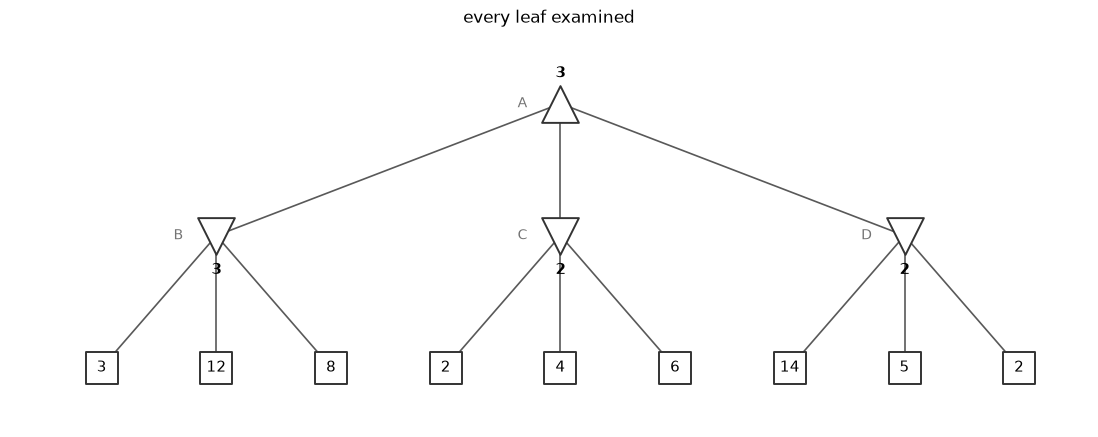

In [6]:
game = TreeGame()
stats = Stats()
value, action = minimax_search(game, game.initial(), stats)

print(f"minimax value {value}, best move {action} (that is node {game.children['A'][action]})")
print(f"{stats}, {len(game.visited)} leaves read: {game.visited}")

draw_tree(game, values={"A": 3, "B": 3, "C": 2, "D": 2}, title="every leaf examined")

Note what MIN did to the promising branches. `B` holds a 12 and `D` holds a 14, but MIN chooses
inside those nodes, so MAX will never see either — `B` is worth 3 and `D` is worth 2. The biggest
number in the tree is irrelevant to the answer.

## Alpha-beta pruning

Now the same search, but carrying the two bounds down the tree.

- `alpha` — the best MAX can already guarantee somewhere along this path. It only rises.
- `beta` — the best MIN can already guarantee. It only falls.

At a MAX node, the moment your running value reaches `beta`, return: MIN has a way to avoid this
node entirely, so its exact value cannot matter. At a MIN node, mirror it against `alpha`.

Two things to get right:
- return **as soon as** the test fires, before looking at the remaining actions
- update `alpha` (at MAX) or `beta` (at MIN) *after* the cutoff test, not before

If your version returns a different value from `minimax_search` on any position, it is wrong —
alpha-beta is not an approximation.

In [11]:
def alphabeta_search(game: Game, state: State, stats: Optional[Stats] = None) -> tuple[float, Action]:
    """Return (minimax value of state, best action) — same answer as minimax_search,
    fewer nodes."""

    def value(state, alpha, beta):
        # TODO
        # count the node in stats, handle the terminal case as minimax_search does
        # at a MAX node: loop over the actions, keep the running best v
        #                if v >= beta: return immediately
        #                otherwise alpha = max(alpha, v)
        # at a MIN node: the mirror image, with v <= alpha and beta = min(beta, v)
        if stats is not None:
            stats.nodes += 1
        if game.is_terminal(state):
            return game.utility(state), None

        if game.to_move(state) == MAX:
            best, best_action = -INF, None
            for a in game.actions(state):
                v, _ = value(game.result(state, a), alpha, beta)
                if v == None:
                    continue
                if v >= beta:
                    return None, None
                else:
                    alpha = max(alpha, v)
                if v > best:
                    best, best_action = v, a
            return best, best_action
        else:
            best, best_action = +INF, None
            for a in game.actions(state):
                v, _ = value(game.result(state, a), alpha, beta)
                if v == None:
                    continue
                if v <= alpha:
                    return None, None
                else:
                    beta = min(beta, v)
                if v < best:
                    best, best_action = v, a
            return best, best_action

    return value(state, -INF, +INF)

alpha-beta value 3, best move 0
11 nodes, 7 leaves read: ['b1', 'b2', 'b3', 'c1', 'd1', 'd2', 'd3']


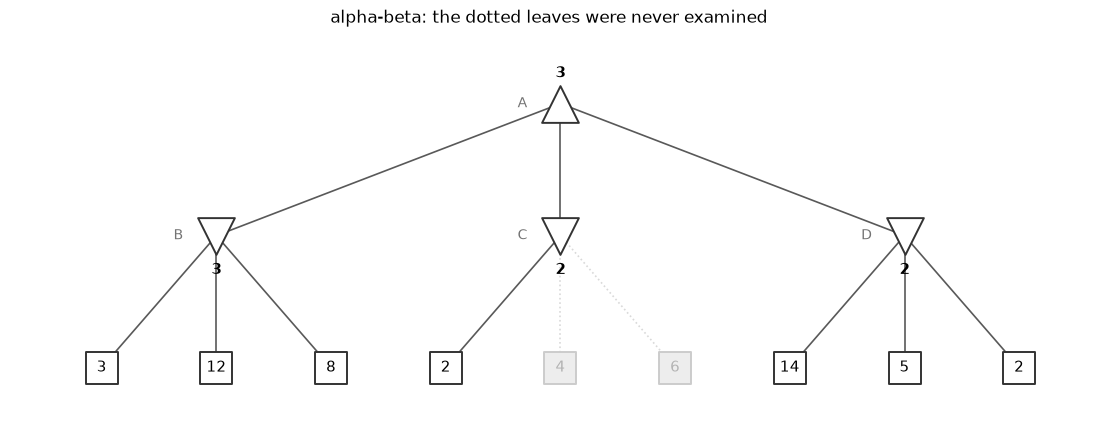

In [12]:
game = TreeGame()
stats = Stats()
value, action = alphabeta_search(game, game.initial(), stats)

print(f"alpha-beta value {value}, best move {action}")
print(f"{stats}, {len(game.visited)} leaves read: {game.visited}")

draw_tree(game, values={"A": 3, "B": 3, "C": 2, "D": 2},
          seen=set(game.visited), title="alpha-beta: the dotted leaves were never examined")

Work through the two cutoffs by hand, because everything later is this:

- **Node C, after its first leaf (2).** MAX has already secured 3 from branch `B`, so `alpha = 3`.
  C is a MIN node whose value is now at most 2. Whatever the leaves 4 and 6 hold, C can only get
  *worse* for MAX, and MAX already has 3 elsewhere. Reading them cannot change the root. Cut.
- **Node D, after 14 and 5.** Still above `alpha = 3`, so the search keeps going and does read the
  last leaf. Not every branch prunes — that depends entirely on the order the values arrive in.

## Ordering decides everything

Same tree, same algorithm, leaves shuffled. The value at the root of each shuffled tree changes,
but the number of leaves read is the point.

In [13]:
def leaves_read(leaves_order, algorithm=None):
    algorithm = algorithm or alphabeta_search
    leaves = dict(zip(TREE_LEAVES.keys(), leaves_order))
    g = TreeGame(TREE_CHILDREN, leaves, "A")
    algorithm(g, g.initial())
    return len(g.visited)


values = list(TREE_LEAVES.values())
print("minimax, any order        ", leaves_read(values, minimax_search), "leaves")
print("alpha-beta, as written    ", leaves_read(values), "leaves")

random.seed(0)
counts = []
for _ in range(2000):
    shuffled = values[:]
    random.shuffle(shuffled)
    counts.append(leaves_read(shuffled))

print(f"alpha-beta, 2000 shuffles  best {min(counts)}, worst {max(counts)}, "
      f"mean {sum(counts) / len(counts):.1f} leaves")

minimax, any order         9 leaves
alpha-beta, as written     7 leaves
alpha-beta, 2000 shuffles  best 5, worst 9, mean 7.3 leaves


## Part 2 — Nim

A real game at last, and a very old one. Some piles of matches; a move takes **any number of
matches, but from one pile only**; whoever takes the last match wins.

Why Nim and not something more familiar: Nim has a closed-form solution. That means we do not have
to trust the search — we can check every answer it gives against mathematics. Almost no game lets
you do that.

The state is a tuple of pile sizes plus whose turn it is. It is a frozen dataclass so it is
hashable and cannot be mutated by accident.

In [30]:
@dataclass(frozen=True)
class NimState:
    piles: tuple[int, ...]
    player: str


class Nim(Game):
    """Normal play: the player who takes the last match wins."""

    def __init__(self, piles=(3, 4, 5)):
        self.piles = tuple(piles)

    def initial(self):
        return NimState(self.piles, MAX)

    def to_move(self, state):
        return state.player

    def actions(self, state):
        # a move is a pair (pile index, how many to take), taking at least 1
        # and at most everything that is left in that pile
        return [(index, number) for index in range(len(state.piles)) for number in range(1, state.piles[index]+1)]

    def result(self, state, action):
        # return a NEW NimState with that pile reduced and the other player to move
        i, k = action
        piles = list(state.piles)
        piles[i] -= k
        return NimState(tuple(piles), other(state.player))


    def is_terminal(self, state):
        return all([True if pile == 0 else False for pile in state.piles])

    def utility(self, state):
        # careful: this is called on a position with no matches left, which means the
        # player to move has nothing to take, so the OTHER player took the last match
        # and won. Return +1 if MAX won, -1 if MIN won.
        return -1 if state.player == MAX else 1


def show_nim(state):
    for i, n in enumerate(state.piles):
        print(f"  pile {i}: " + "|" * n + f"  ({n})")
    print(f"  to move: {state.player}")

In [31]:
nim = Nim((1, 2, 3))
show_nim(nim.initial())

stats_mm, stats_ab = Stats(), Stats()
v1, a1 = minimax_search(nim, nim.initial(), stats_mm)
v2, a2 = alphabeta_search(nim, nim.initial(), stats_ab)

print(f"\nminimax    value {v1:+d}, move {a1}, {stats_mm}")
print(f"alpha-beta value {v2:+d}, move {a2}, {stats_ab}")

  pile 0: |  (1)
  pile 1: ||  (2)
  pile 2: |||  (3)
  to move: MAX

minimax    value -1, move (0, 1), 447 nodes
alpha-beta value -1, move (0, 1), 249 nodes


A value of `-1` means MAX loses this position however well MAX plays. Now a bigger one, where the
difference between the two algorithms stops being cosmetic.

In [32]:
nim = Nim((3, 4, 5))

start = time.perf_counter()
stats_mm = Stats()
v1, a1 = minimax_search(nim, nim.initial(), stats_mm)
t_mm = time.perf_counter() - start

start = time.perf_counter()
stats_ab = Stats()
v2, a2 = alphabeta_search(nim, nim.initial(), stats_ab)
t_ab = time.perf_counter() - start

print(f"{'':<12}{'value':>7}{'move':>10}{'nodes':>12}{'seconds':>10}")
print(f"{'minimax':<12}{v1:>+7d}{str(a1):>10}{stats_mm.nodes:>12,}{t_mm:>10.3f}")
print(f"{'alpha-beta':<12}{v2:>+7d}{str(a2):>10}{stats_ab.nodes:>12,}{t_ab:>10.3f}")
print(f"\nsame answer, {stats_mm.nodes / stats_ab.nodes:.0f}x fewer nodes")

              value      move       nodes   seconds
minimax          +1    (0, 2)   1,038,768     1.101
alpha-beta       +1    (0, 2)      33,916     0.034

same answer, 31x fewer nodes


### Checking the search against mathematics

Nim's solution is the **nim-sum**: the bitwise XOR of the pile sizes. The theorem says the player
whose turn it is **loses** exactly when the nim-sum is zero, and the winning move is always the one
that hands the opponent a nim-sum of zero.

That gives us something we have not had all semester: an oracle that knows the right answer without
searching. So we can test the search rather than admire it.

In [33]:
def nim_sum(piles) -> int:
    total = 0
    for n in piles:
        total ^= n
    return total


def nim_oracle(state) -> int:
    """The true minimax value, from the theorem, with no search at all."""
    losing_for_mover = nim_sum(state.piles) == 0
    mover_is_max = state.player == MAX
    return -1 if losing_for_mover == mover_is_max else +1


import itertools

checked = mismatches = bad_moves = 0
for piles in itertools.product(range(5), repeat=3):
    for player in (MAX, MIN):
        g, s = Nim(piles), NimState(piles, player)
        expected = nim_oracle(s)
        v_mm, _ = minimax_search(g, s)
        v_ab, action = alphabeta_search(g, s)
        checked += 1
        if v_mm != expected or v_ab != expected:
            mismatches += 1
            print("MISMATCH", piles, player, v_mm, v_ab, expected)
        mover_wins = expected == (+1 if player == MAX else -1)
        if mover_wins and action is not None and nim_sum(g.result(s, action).piles) != 0:
            bad_moves += 1
            print("BAD MOVE", piles, player, action)

print(f"{checked} positions checked, {mismatches} wrong values, {bad_moves} wrong moves")

250 positions checked, 0 wrong values, 0 wrong moves


Every winning move the search found leaves the opponent a nim-sum of zero — which is what the
theorem says the winning move is. The search rediscovered the mathematics without being told it.

### Playing it out

One helper that runs a whole game between two move-choosing functions.

In [34]:
def play(game, players: dict[str, Callable], state=None, verbose=False):
    """players maps MAX and MIN to a function (game, state) -> action."""
    state = game.initial() if state is None else state
    while not game.is_terminal(state):
        action = players[game.to_move(state)](game, state)
        if verbose:
            print(f"{game.to_move(state)} plays {action}")
        state = game.result(state, action)
    return state


def optimal_player(game, state):
    return alphabeta_search(game, state)[1]


def random_player(game, state):
    return random.choice(game.actions(state))


random.seed(2)
nim = Nim((3, 4, 5))
final = play(nim, {MAX: optimal_player, MIN: random_player}, verbose=True)
print(f"\nfinal utility to MAX: {nim.utility(final):+d}")

wins = sum(nim.utility(play(nim, {MAX: optimal_player, MIN: random_player})) == 1
           for _ in range(20))
print(f"optimal MAX vs random MIN from (3,4,5): {wins}/20 wins")

MAX plays (0, 2)
MIN plays (0, 1)
MAX plays (2, 1)
MIN plays (1, 2)
MAX plays (2, 2)
MIN plays (1, 1)
MAX plays (2, 1)
MIN plays (2, 1)
MAX plays (1, 1)

final utility to MAX: +1
optimal MAX vs random MIN from (3,4,5): 20/20 wins


Twenty out of twenty, because `(3, 4, 5)` has nim-sum `3 ^ 4 ^ 5 = 2`, which is not zero — so it is
won for the player to move, and an optimal player never lets go of a won position. Start from a
nim-sum of zero, such as `(1, 2, 3)`, and the same player loses every game against anyone who does
not blunder.

## Part 3 — Connect Four

Six rows, seven columns, drop a piece into a column and it falls to the bottom. Four in a row in
any direction wins.

The game tree has roughly 4.5 trillion positions. Minimax will not reach the leaves, ever, so this
is where the last two ideas from the README have to do the work: **stop early**, and **guess what
the position is worth**.

In [14]:
ROWS, COLS = 6, 7


def cell(row, col):
    return row * COLS + col


# every group of four cells in a line: horizontal, vertical, both diagonals
WINDOWS = []
for r in range(ROWS):
    for c in range(COLS):
        if c + 3 < COLS:
            WINDOWS.append([cell(r, c + i) for i in range(4)])
        if r + 3 < ROWS:
            WINDOWS.append([cell(r + i, c) for i in range(4)])
        if c + 3 < COLS and r + 3 < ROWS:
            WINDOWS.append([cell(r + i, c + i) for i in range(4)])
        if c - 3 >= 0 and r + 3 < ROWS:
            WINDOWS.append([cell(r + i, c - i) for i in range(4)])

# the windows passing through each cell, so a win check only looks near the last move
WINDOWS_AT = [[] for _ in range(ROWS * COLS)]
for w in WINDOWS:
    for i in w:
        WINDOWS_AT[i].append(w)

print(f"{len(WINDOWS)} four-in-a-row lines on a {ROWS}x{COLS} board")

69 four-in-a-row lines on a 6x7 board


In [16]:
@dataclass(frozen=True)
class C4State:
    cells: tuple[str, ...]      # ROWS * COLS of '.', 'X' (MAX) or 'O' (MIN), row 0 on top
    player: str
    winner: Optional[str] = None
    moves: int = 0


class ConnectFour(Game):
    def initial(self):
        return C4State(tuple("." * (ROWS * COLS)), MAX)

    def to_move(self, state):
        return state.player

    def actions(self, state):
        return [c for c in range(COLS) if state.cells[cell(0, c)] == "."]

    def result(self, state, col):
        row = max(r for r in range(ROWS) if state.cells[cell(r, col)] == ".")
        i = cell(row, col)
        cells = list(state.cells)
        cells[i] = "X" if state.player == MAX else "O"
        cells = tuple(cells)
        mark = cells[i]
        won = any(all(cells[j] == mark for j in w) for w in WINDOWS_AT[i])
        return C4State(cells, other(state.player),
                       state.player if won else None, state.moves + 1)

    def is_terminal(self, state):
        return state.winner is not None or state.moves == ROWS * COLS

    def utility(self, state):
        if state.winner == MAX:
            return +1000
        if state.winner == MIN:
            return -1000
        return 0


def show_board(state):
    for r in range(ROWS):
        print(" " + " ".join(state.cells[cell(r, c)] for c in range(COLS)))
    # print(" " + " ".join(str(c) for c in range(COLS)))


board = ConnectFour()
s = board.initial()
for col in (3, 3, 4, 2, 5):
    s = board.result(s, col)
show_board(s)

 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . O X X X .


### An evaluation function

MAX is `X`, MIN is `O`, and the search will stop long before anyone wins, so it needs a number for
an unfinished position. The standard recipe: look at every line of four cells, and score the ones
that are still *live* — cells belonging to one player and empty squares, with no enemy piece in the
way. A line with three of your pieces and a gap is worth far more than three scattered singles.

Two properties the README asks for, worth checking as you write it:
- it must be **cheap**, because it runs at every leaf of the cutoff search
- its sign and rough size must **agree with who is winning**; the exact numbers matter much less

Suggested weights: one piece in a live line `1`, two `10`, three `50`, and negate it for MIN's
lines. A small bonus for the centre column helps, because the centre takes part in more lines than
any other column.

In [35]:
SCORE = {1: 1, 2: 10, 3: 50}
from collections import Counter

def evaluate(state: C4State) -> float:
    """An estimate of how good the position is for MAX. Positive favours X."""
    # for every window in WINDOWS:
    #   count the X's and the O's in it
    #   if it holds only X's and blanks, add SCORE[number of X's]
    #   if it holds only O's and blanks, subtract SCORE[number of O's]
    # then add a small bonus per X in the centre column and subtract one per O
    total = 0
    for window in WINDOWS:
        xs = os = 0
        for i in window:
            v = state.cells[i]
            if v == "X":
                xs += 1
            elif v == "O":
                os += 1
        if xs and not os:        # a line only X can still complete
            total += SCORE[xs]
        elif os and not xs:      # a line only O can still complete
            total -= SCORE[os]
    middle = COLS // 2
    for r in range(ROWS):
        v = state.cells[cell(r, middle)]
        if v == "X":
            total += 3
        elif v == "O":
            total -= 3
    return total

### Minimax with a cutoff

Two changes to the algorithm, and no more:

- a `depth` counter, and when it hits zero return `eval_fn(state)` instead of recursing
- terminal states still use `game.utility`, because there the true answer is known

The `order` argument is optional and takes `(state, actions) -> actions`. It changes nothing about
the result and a great deal about the cost.

In [45]:
def alphabeta_cutoff_search(game, state, depth: int, eval_fn,
                            order=None, stats: Optional[Stats] = None):
    """Alpha-beta, but stop at the given depth and estimate with eval_fn."""

    def value(state, depth, alpha, beta):
        # TODO
        # count the node
        # if the game is over: return game.utility(state), None
        # if depth == 0: return eval_fn(state), None
        # otherwise take game.actions(state), pass them through order if it was given,
        # and do exactly what alphabeta_search does, recursing with depth - 1
        if stats is not None:
            stats.nodes += 1
        if game.is_terminal(state):
            return game.utility(state), None
        if depth == 0:
            return eval_fn(state), None
        actions = order(game.actions(state))
        best, best_action = (-INF, actions[0]) if game.to_move(state) == MAX else (+INF, actions[0])
        for a in actions:
            v, _ = value(game.result(state, a), depth - 1, alpha, beta)
            if v is None:
                continue
            if v >= beta and game.to_move(state) == MAX or v <= alpha and game.to_move(state) == MIN:
                return None, None
            if game.to_move(state) == MAX:
                alpha = max(alpha, v)
            if game.to_move(state) == MIN:
                beta = min(beta, v)

            if (game.to_move(state) == MAX and v > best) or (game.to_move(state) == MIN and v < best):
                best, best_action = v, a
            
        return best, best_action

    return value(state, depth, -INF, +INF)


def minimax_cutoff_search(game, state, depth: int, eval_fn, stats: Optional[Stats] = None):
    """The same cutoff search with no pruning, for comparison."""

    def value(state, depth):
        if stats is not None:
            stats.nodes += 1
        if game.is_terminal(state):
            return game.utility(state), None
        if depth == 0:
            return eval_fn(state), None
        actions = game.actions(state)
        best, best_action = (-INF, actions[0]) if game.to_move(state) == MAX else (+INF, actions[0])
        for a in actions:
            v, _ = value(game.result(state, a), depth - 1)
            if (game.to_move(state) == MAX and v > best) or (game.to_move(state) == MIN and v < best):
                best, best_action = v, a
        return best, best_action

    return value(state, depth)

Before measuring anything, check that the search plays sensibly: it should take a win when one is
available, and block the opponent's when one is not.

In [41]:
board = ConnectFour()

# X has three in a row along the bottom; column 3 wins immediately
s = board.initial()
for col in (0, 0, 1, 1, 2, 2):
    s = board.result(s, col)
show_board(s)
print("X to move, best:", alphabeta_cutoff_search(board, s, 4, evaluate)[1], "(should be 3)")

# now O is the one with three in a row, and X has to block
s = board.initial()
for col in (6, 0, 5, 1, 4, 2):
    s = board.result(s, col)
print()
show_board(s)
print("O to move, best:", alphabeta_cutoff_search(board, s, 4, evaluate)[1], "(should be 3)")

 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 O O O . . . .
 X X X . . . .
X to move, best: 3 (should be 3)

 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 O O O . X X X
O to move, best: 3 (should be 3)


### What ordering is worth

The README claims perfect ordering takes alpha-beta from `O(b^m)` to `O(b^(m/2))`, with random
ordering somewhere in between. Connect Four is big enough to see it.

The ordering here is about as cheap as an ordering gets — try the middle columns first, because
they take part in more winning lines — and it is nowhere near perfect. It does not have to be.

In [42]:
CENTRE_FIRST = sorted(range(COLS), key=lambda c: abs(c - COLS // 2))


def centre_order(state, actions):
    return [c for c in CENTRE_FIRST if c in actions]


def shuffled_order(state, actions):
    actions = list(actions)
    random.shuffle(actions)
    return actions


board = ConnectFour()
start_state = board.initial()

print(f"{'depth':>6}{'minimax':>12}{'alpha-beta':>13}{'+ random':>11}{'+ centre':>11}")
random.seed(3)
for depth in (4, 6):
    s_mm, s_ab, s_ce = Stats(), Stats(), Stats()
    minimax_cutoff_search(board, start_state, depth, evaluate, s_mm)
    alphabeta_cutoff_search(board, start_state, depth, evaluate, None, s_ab)
    alphabeta_cutoff_search(board, start_state, depth, evaluate, centre_order, s_ce)
    rnd = []
    for _ in range(5):
        s_rd = Stats()
        alphabeta_cutoff_search(board, start_state, depth, evaluate, shuffled_order, s_rd)
        rnd.append(s_rd.nodes)
    print(f"{depth:>6}{s_mm.nodes:>12,}{s_ab.nodes:>13,}{sum(rnd) // len(rnd):>11,}{s_ce.nodes:>11,}")

 depth     minimax   alpha-beta   + random   + centre
     4       2,801          976        976        976
     6     137,257       17,364     17,364     17,364


All four columns compute the same move. The only thing that changed is how much work it took, and
a seven-line ordering function is worth more than the pruning was.

### Does searching deeper actually play better

The whole argument for pruning is that the nodes it saves buy depth, and that depth buys strength.
Worth confirming rather than assuming.

In [43]:
def cutoff_player(depth, order=centre_order):
    def player(game, state):
        return alphabeta_cutoff_search(game, state, depth, evaluate, order)[1]
    return player


board = ConnectFour()


def random_opening(rng, plies=2):
    """Both players are deterministic, so vary the starting position instead."""
    state = board.initial()
    for _ in range(plies):
        state = board.result(state, rng.choice(board.actions(state)))
    return state


def match(deep_depth, shallow_depth, games=20):
    deep, shallow = cutoff_player(deep_depth), cutoff_player(shallow_depth)
    rng = random.Random(11)
    won = lost = drawn = 0
    for _ in range(games):
        state = random_opening(rng)
        mover = board.to_move(state)                      # the deeper player takes this side
        final = play(board, {mover: deep, other(mover): shallow}, state=state)
        score = board.utility(final) * (1 if mover == MAX else -1)
        won, lost, drawn = won + (score > 0), lost + (score < 0), drawn + (score == 0)
    return won, lost, drawn


print("deeper player vs a depth 2 player, 20 games from random 2-ply openings\n")
print(f"{'depth':>6}{'won':>6}{'lost':>6}{'drawn':>7}")
for depth in (3, 4, 5, 6):
    won, lost, drawn = match(depth, 2)
    print(f"{depth:>6}{won:>6}{lost:>6}{drawn:>7}")

deeper player vs a depth 2 player, 20 games from random 2-ply openings

 depth   won  lost  drawn
     3     6    10      4
     4    10     9      1
     5    18     2      0
     6    12     6      2


Not the clean staircase you might expect. Depth 4 and depth 5 beat the shallow player
comfortably, but **depth 3 loses to depth 2**, and **depth 6 does worse than depth 5** against the
same opponent.

Nothing is broken. All six players run the identical algorithm with the identical evaluation
function, and the search is exact down to its cutoff — the difference is entirely in what the
cutoff leaves them guessing about. A search that stops after MAX's own move sees a position where
MAX has just improved things and MIN has not yet replied, which flatters it; stopping one ply later
does the reverse. So the estimate swings with the **parity** of the depth, and a crude evaluation
function cannot damp that out. This is the odd-even effect, and it is why real engines search to a
fixed parity, or extend unstable positions rather than stopping on them.

The lesson is not that depth is useless. It is that below the cutoff the answer stops being
proved and starts being estimated, and every guarantee from the first half of this notebook applies
only above the line. Alpha-beta never costs you anything; the cutoff can cost you a great deal.

### Play it yourself

Run this cell and type a column number to move. The search plays `O`.

In [44]:
def play_connect_four(depth=5):
    board = ConnectFour()
    state = board.initial()
    while not board.is_terminal(state):
        show_board(state)
        if board.to_move(state) == MAX:
            legal = board.actions(state)
            try:
                col = int(input(f"your column {legal}: "))
            except (ValueError, EOFError):
                print("stopped")
                return
            if col not in legal:
                print("not a legal column")
                continue
        else:
            start = time.perf_counter()
            col = alphabeta_cutoff_search(board, state, depth, evaluate, centre_order)[1]
            print(f"O plays {col}  ({time.perf_counter() - start:.2f}s)")
        state = board.result(state, col)

    show_board(state)
    print({MAX: "you win", MIN: "O wins", None: "a draw"}[state.winner])


play_connect_four()

 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . X . . .
O plays 3  (0.05s)
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . . X . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . . X X . .
O plays 2  (0.06s)
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . O X X . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . O X X X .
O plays 6  (0.13s)
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . O . . .
 . . O X X X O
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . X O . . .
 . . O X X X O
O plays 5  (0.11s)
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . X O . O .
 . . O X X X O
 . . . . . . .
 . . . . . . .
 . . . . . . .
 . . X . . . .
 . . X O . O .
 . . O X X X O
O plays 4  (0.10s)
 . . 

## Where this leaves us

- Minimax **defines** correct play, and is unusable beyond toy games.
- Alpha-beta returns **exactly the same value** for a fraction of the nodes. Nothing is
  approximated, nothing is risked — the skipped subtrees were proved irrelevant first.
- What alpha-beta actually saves depends on move ordering, and a crude ordering recovers most of
  the possible gain. On the Connect Four table above, ordering bought more than pruning did.
- For a real game you also need a **cutoff** and an **evaluation function**, and from that point on
  the search is only as good as its guess about unfinished positions.

Nim is the part to remember when it goes wrong. A search that agrees with an independent oracle on
every position is a search you have tested; one that merely looks reasonable is not.